PREPROCESAMIENTO

El objetivo final será obtener dos conjuntos de datos independientes, representativos y adecuados para el entrenamiento y la evaluación de los modelos de clasificación.

Arrancamos con una celda limpia de configuración que centralice rutas y cree la carpeta de salida data/processed/ si no existe, verificando que los archivos crudos estén exactamente donde esperamos antes de tocar un solo dato.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

# Configuración global de reproducibilidad
RANDOM_STATE = 42

# Rutas del proyecto (asumiendo ejecución desde notebooks/)
ROOT_DIR = Path("..").resolve()
DATA_RAW = ROOT_DIR / "data" / "raw"
DATA_PROCESSED = ROOT_DIR / "data" / "processed"
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)

# Rutas específicas de cada dataset
KAGGLE_DIR = DATA_RAW / "dataset_kaggle"  # Ajustar si el nombre de carpeta difiere
GITHUB_DIR = DATA_RAW / "dataset_github" / "data"

print(f"Raíz del proyecto : {ROOT_DIR}")
print(f"Salida procesada  : {DATA_PROCESSED}")
print(f"Kaggle existe     : {KAGGLE_DIR.exists()} -> {[p.name for p in KAGGLE_DIR.glob('*.csv')] if KAGGLE_DIR.exists() else 'Verificar ruta'}")
print(f"GitHub viajes     : {sorted([p.name for p in GITHUB_DIR.iterdir() if p.is_dir()]) if GITHUB_DIR.exists() else 'Verificar ruta'}")

Raíz del proyecto : /home/matias-muller/Documents/Programacion/tp-ia-driving-behavior
Salida procesada  : /home/matias-muller/Documents/Programacion/tp-ia-driving-behavior/data/processed
Kaggle existe     : True -> ['sensor_raw.csv', 'sero_features_8.csv', 'sero_features_19.csv', 'sero_features_11.csv', 'sero_features_9.csv', 'sero_features_13.csv', 'sero_features_17.csv', 'sero_features_20.csv', 'sero_features_7.csv', 'sero_features_15.csv', 'sero_features_6.csv', 'sero_features_12.csv', 'sero_features_18.csv', 'sero_features_10.csv', 'features_14.csv', 'sero_features_16.csv', 'sero_features_5.csv', 'sero_features_4.csv']
GitHub viajes     : ['16', '17', '20', '21']


----------------------------------------------------------------------------------------------------------------------------------------------

BLOQUE A (KAGGLE)

cargaremos features_14.csv (la ventana recomendada). Eliminaremos las 12 columnas redundantes matematicamente (Sum y Var) y descartaremos las 10 ventanas incompletas al inicio de cada clase (las que tienen entre 4 y 13 muestras en lugar de 14):

In [2]:
# Cargamos features_14.csv de Kaggle 
df_kaggle = pd.read_csv(KAGGLE_DIR / "features_14.csv")

# Definimos la columna objetivo
TARGET_COL = "Target"

print(f"Shape original: {df_kaggle.shape}")

Shape original: (1102, 61)


In [3]:
# Eliminamos columnas matemáticamente determinísticas (Sum = 14*Mean y Var = Std^2)
cols_deterministicas = [
    c for c in df_kaggle.columns
    if c != TARGET_COL and ("sum" in c.lower() or "var" in c.lower())
]
df_kaggle_clean = df_kaggle.drop(columns=cols_deterministicas)

print(f"Columnas determinísticas eliminadas ({len(cols_deterministicas)}):")
print(cols_deterministicas)

Columnas determinísticas eliminadas (12):
['AccSumX', 'AccSumY', 'AccSumZ', 'AccVarX', 'AccVarY', 'AccVarZ', 'GyroSumX', 'GyroSumY', 'GyroSumZ', 'GyroVarX', 'GyroVarY', 'GyroVarZ']


In [4]:
# Descartamos las primeras 10 filas de cada clase. Osea las ventanas incompletas de 4 a 13 muestras
# En el EDA comprobamos que al aplicar el metodo de ventanas se dejaron 10 filas incompletas al inicio de cada bloque
df_kaggle_clean = (
    df_kaggle_clean
    .groupby(TARGET_COL, group_keys=False) # Agrupamos por clase sin crear un índice jerárquico
    .apply(lambda g: g.iloc[10:]) # Descarte de las primeras 10 filas de cada clase
    .reset_index(drop=True)
)

print(f"\nShape tras limpieza: {df_kaggle_clean.shape}")
print("\nDistribución de clases:")
print(df_kaggle_clean[TARGET_COL].value_counts())


Shape tras limpieza: (1062, 49)

Distribución de clases:
Target
3    337
2    275
1    239
4    211
Name: count, dtype: int64


/tmp/ipykernel_150370/1909854393.py:6: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.iloc[10:]) # Descarte de las primeras 10 filas de cada clase


In [5]:
df_kaggle_clean.head(14)

,Target,AccMeanX,AccMeanY,AccMeanZ,AccCovX,AccCovY,AccCovZ,AccSkewX,AccSkewY,AccSkewZ,...,GyroMinZ,GyroMaxX,GyroMaxY,GyroMaxZ,GyroMedianX,GyroMedianY,GyroMedianZ,GyroStdX,GyroStdY,GyroStdZ
0,1,0.308245,-0.158970,-0.958583,0.015166,0.004274,0.001710,0.169246,-0.577856,0.850181,...,-2.221374,3.351145,8.725191,0.877863,-0.874046,4.026718,0.393130,1.332340,1.467743,1.007677
1,1,0.337873,-0.174020,-0.950823,0.018161,0.005101,0.002371,0.174542,-0.439926,0.684742,...,-2.221374,3.351145,8.725191,1.198473,-0.484733,4.026718,0.393130,1.371523,1.805248,1.036329
2,1,0.350115,-0.172015,-0.953613,0.015985,0.005474,0.002855,0.060480,-0.346555,0.230124,...,-2.221374,3.351145,8.725191,1.450382,-0.183206,3.847328,0.393130,1.350928,2.011375,1.086169
3,1,0.362095,-0.169817,-0.957502,0.017288,0.005692,0.002715,-0.156096,-0.384714,0.461695,...,-2.221374,3.351145,8.725191,1.450382,-0.538168,3.690840,0.446565,1.347780,2.067952,1.090596
4,1,0.360317,-0.171701,-0.951399,0.016880,0.005973,0.003509,-0.148172,-0.349213,0.465243,...,-2.221374,3.351145,8.725191,1.946565,-0.538168,3.690840,0.694656,1.436964,2.433518,1.195623
5,1,0.341169,-0.158238,-0.956124,0.019303,0.006126,0.003809,0.077702,-0.615954,0.575238,...,-2.221374,1.770992,8.725191,1.946565,-0.725191,3.904580,0.717557,1.063558,2.406864,1.201909
6,1,0.324881,-0.154000,-0.960972,0.021522,0.006529,0.003758,0.272945,-0.669740,0.833572,...,-2.221374,1.770992,8.725191,1.946565,-0.679389,4.095420,0.759542,1.016049,2.392481,1.069365
7,1,0.321429,-0.148908,-0.974609,0.021095,0.005759,0.003471,0.350482,-0.823967,0.999146,...,-2.221374,1.770992,8.526718,1.946565,-0.679389,4.095420,0.793893,0.906349,2.047043,1.050251
8,1,0.333566,-0.154419,-0.963065,0.023824,0.005678,0.005452,0.197913,-0.610279,0.980059,...,-2.221374,1.770992,8.526718,1.946565,-0.599237,3.904580,0.793893,0.884071,2.081477,0.988047
9,1,0.359776,-0.151437,-0.967442,0.030226,0.005140,0.006146,0.118396,-0.643317,0.806495,...,0.198473,1.770992,9.213740,1.946565,-0.599237,3.904580,0.812977,0.986258,2.517508,0.555210


Sacar Sum y Var es razonable (si la ventana siempre mide 14, la suma es exactamente 14 × media y la varianza es desvío²), al igual que quitar las primeras 10 filas por clase, asegura que todas las filas restantes representen la misma duración real de manejo. La única contra es perder 40 registros, un costo mínimo a cambio de eliminar ventanas ruidosas con distinto tamaño de muestra.

Procederemos a ejecutar el split 70/30 por bloques contiguos por clase y sin mezclar, descartando un margen de 13 filas en cada corte para eliminar cualquier posible solapamiento entre entrenamiento y test (con esto nos aseguramos). el fundamento nace porque features_14 agrupa las maniobras por clase de forma secuencial, entonces cortamos el primer 70% de cada clase para train y el ultimo 30% para test, manteniendo exactamente el mismo balance de clases en ambos conjuntos.

In [6]:
EMBARGO = 13 # Número de filas descartadas al final de cada bloque para evitar leakage
TRAIN_RATIO = 0.70 # Porcentaje de bloques para entrenamiento

In [7]:
# Creamos listas para almacenar los bloques de entrenamiento y prueba
train_blocks = []
test_blocks = []

# Iteramos sobre cada clase y dividimos en bloques contiguos con embargo
for cls, grupo in df_kaggle_clean.groupby(TARGET_COL, sort=True):
    n_util = len(grupo) - EMBARGO # Número de filas útiles para split (descontando embargo)
    corte_train = int(n_util * TRAIN_RATIO) # Número de filas para entrenamiento (70% de las filas útiles)
    
    train_blocks.append(grupo.iloc[:corte_train]) # Agregamos el bloque de entrenamiento
    test_blocks.append(grupo.iloc[corte_train + EMBARGO:]) # Agregamos el bloque de prueba (descontando embargo)

# Concatenamos los bloques de entrenamiento y prueba en DataFrames finales
df_kaggle_train = pd.concat(train_blocks, ignore_index=True) 
df_kaggle_test = pd.concat(test_blocks, ignore_index=True)

print(f"Total antes del split : {len(df_kaggle_clean)}")
print(f"Filas descartadas     : {len(df_kaggle_clean) - len(df_kaggle_train) - len(df_kaggle_test)} (13 por clase)")
print(f"Train shape           : {df_kaggle_train.shape} ({len(df_kaggle_train) / (len(df_kaggle_train) + len(df_kaggle_test)):.1%})")
print(f"Test shape            : {df_kaggle_test.shape} ({len(df_kaggle_test) / (len(df_kaggle_train) + len(df_kaggle_test)):.1%})")

Total antes del split : 1062
Filas descartadas     : 52 (13 por clase)
Train shape           : (705, 49) (69.8%)
Test shape            : (305, 49) (30.2%)


Perder 52 filas en los cortes es un precio mínimo que estamos dispuestos a pagar, sin ese pequeño margen, el modelo vería en test casi los mismos segundos de manejo que ya memorizó en train. Ademas existe la limitacion de no tener Driver_ID, no podemos garantizar que los tres conductores queden separados entre entrenamiento y prueba; por eso este corte protege contra fuga temporal entre ventanas, pero no mide generalización a un conductor nuevo.

In [8]:
# Resumen de clases en train y test
resumen_clases = pd.DataFrame({
    "Train (n)": df_kaggle_train[TARGET_COL].value_counts().sort_index(),
    "Test (n)": df_kaggle_test[TARGET_COL].value_counts().sort_index(),
    "Train (%)": (df_kaggle_train[TARGET_COL].value_counts(normalize=True).sort_index() * 100).round(1),
    "Test (%)": (df_kaggle_test[TARGET_COL].value_counts(normalize=True).sort_index() * 100).round(1),
})
display(resumen_clases)

,Train (n),Test (n),Train (%),Test (%)
Target,,,,
1,158,68,22.4,22.3
2,183,79,26.0,25.9
3,226,98,32.1,32.1
4,138,60,19.6,19.7


El split quedo bien, 69,8% train / 30,2% test con proporciones casi identicas por clase

Analizaremos sobre df_kaggle_train (datos de entrenamiento) si detectamos mas columnas redundantes por alta correlacion calculando la matriz de correlacion

¿Por que ahora? porque eliminar variables que podrian ser casi identicas reduce ruido y hace el modelo mas interpretable, lo calculamos solo sobre train para respetar la regla: ninguna decision estadistica puede usar informacion de test.

Usamos un umbral conservador de $\vert{}r\vert{} \ge 0.90$ para ver exactamente qué pares están duplicando información antes de borrar nada:

In [9]:
# Análisis de colinealidad SOLO sobre X_train
UMBRAL_CORR = 0.90

X_train_kaggle = df_kaggle_train.drop(columns=[TARGET_COL])
corr_matrix = X_train_kaggle.corr().abs()

# Extraer solo la parte superior para no repetir pares ni incluir la diagonal
pares_altos = []
cols = corr_matrix.columns

for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        val = corr_matrix.iloc[i, j]
        if val >= UMBRAL_CORR:
            pares_altos.append({
                "Feature_A": cols[i],
                "Feature_B": cols[j],
                "Corr_Abs": round(val, 4)
            })

df_pares = pd.DataFrame(pares_altos).sort_values("Corr_Abs", ascending=False).reset_index(drop=True)
print(f"Pares con |r| >= {UMBRAL_CORR}: {len(df_pares)}")
display(df_pares)

Pares con |r| >= 0.9: 9


,Feature_A,Feature_B,Corr_Abs
0,GyroCovZ,GyroStdZ,0.9889
1,AccCovZ,AccStdZ,0.9814
2,GyroCovY,GyroStdY,0.9811
3,AccCovY,AccStdY,0.9802
4,GyroCovX,GyroStdX,0.9776
5,AccCovX,AccStdX,0.9767
6,AccMaxY,GyroMaxZ,0.9222
7,AccMinY,GyroMinZ,0.9071
8,AccMeanY,GyroMeanZ,0.9052


Viendo esto, eliminaremos únicamente las 6 columnas Cov (redundancia estadística casi exacta con Std, $\vert{}r\vert{} \ge 0.976$), conservamos Std porque es la medida de dispersión más estándar. Ademas, sera mejor conservar los pares AccY vs. GyroZ, ya que pertenecen a sensores distintos y reflejan un fenómeno físico real (aceleración lateral y giro al doblar), no una duplicación de cálculo. Con esto cerramos y guardamos el dataset de Kaggle.

In [ ]:
import pyarrow as pa

# Eliminación de columnas redundantes (decidida solo en train)
cols_drop_corr = [
    "AccCovX", "AccCovY", "AccCovZ",
    "GyroCovX", "GyroCovY", "GyroCovZ"
]

df_kaggle_train_final = df_kaggle_train.drop(columns=cols_drop_corr)
df_kaggle_test_final = df_kaggle_test.drop(columns=cols_drop_corr)

# Verificación final antes de guardar
assert list(df_kaggle_train_final.columns) == list(df_kaggle_test_final.columns)
assert df_kaggle_train_final.isna().sum().sum() == 0
assert df_kaggle_test_final.isna().sum().sum() == 0

# Exportación (esta vez usaremos pyarrow que ya esta instalado)
train_path = DATA_PROCESSED / "kaggle_train.parquet"
test_path = DATA_PROCESSED / "kaggle_test.parquet"

# guardamos los datasets finales en formato parquet
df_kaggle_train_final.to_parquet(train_path, index=False)
df_kaggle_test_final.to_parquet(test_path, index=False)

print(f"Kaggle Train guardado : {train_path.name} -> {df_kaggle_train_final.shape}")
print(f"Kaggle Test guardado  : {test_path.name} -> {df_kaggle_test_final.shape}")
print(f"Features finales      : {df_kaggle_train_final.shape[1] - 1} + 1 Target")

Kaggle Train guardado : kaggle_train.parquet -> (705, 43)
Kaggle Test guardado  : kaggle_test.parquet -> (305, 43)
Features finales      : 42 + 1 Target


Kaggle ya quedo cerrado y listo para modelar (kaggle_train.parquet y kaggle_test.parquet)! Guardamos los .parquet en la ruta data/processed. este formato no permite visualizar el archivo directamente porque guarda los datos en binario, pero busque en internet y es mas eficiente para trabajar en proyectos asi. Si se desea chusmearlos se puede facilmente ejecutar algo del estilo: 
df = pd.read_parquet(DATA_PROCESSED / "kaggle_train.parquet")
display(df) para posterior visualizacion

----------------------------------------------------------------------------------------------------------------------------------------------

BLOQUE B (GITHUB)

Primero y recordando lo del EDA, vamos a cargar y sincronizar los 4 viajes en una celda limpia para verificar que los 69 eventos etiquetados tengan cobertura completa de muestras en acelerómetro y giroscopio antes de extraer características.

1) Carga de los 4 viajes (16, 17, 20, 21), sincronización a segundos y verificación de que ningún evento quede vacío o mal alineado

uptimeNanos: instante en el que se registró cada medición, expresado en nanosegundos.
t0_nanos: instante en el que comenzó la recolección de datos del viaje, también expresado en nanosegundos.

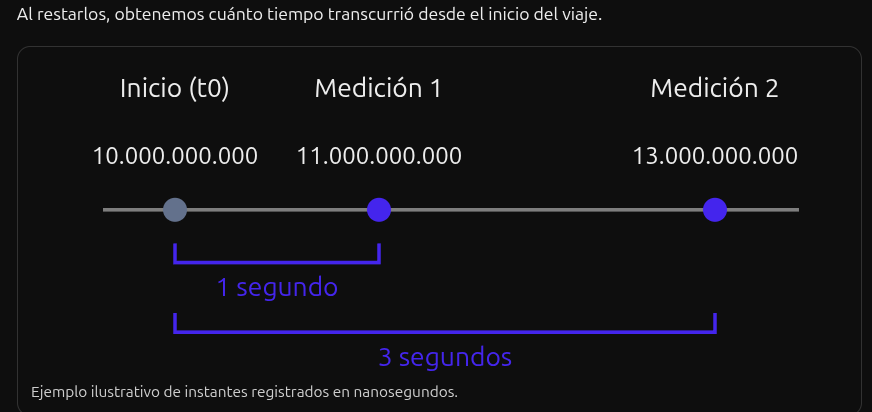

In [11]:
TRIPS = ["16", "17", "20", "21"]

En GitHub tenemos lo siguiente, hay sensores que graban ~51 mediciones por segundo (~50,9 Hz) y el archivo groundTruth.csv que solo dice "entre el segundo 120,5 y el 122,1 hubo una frenada brusca". Cuando cruzamos ambos archivos, podrían pasar problemas sin advertirlos

Sabemos del EDA que el evento más corto dura 1,6 segundos. A ~50,9 Hz, ese evento debería tener alrededor de $1,6 \times 50,9 \approx 81$ muestras.

Si el minimo de muestras de los atributos nos dan cerca de ~80 (o más), podremos confirmar que todos los eventos de ese viaje están bien sincronizados y completos.

Por eso procuraremos chequear la cobertura mínima de muestras para asegurarnos de que, al recortar cada maniobra con los tiempos del groundTruth.csv, efectivamente caigan suficientes lecturas reales de los sensores dentro de ese intervalo y no haya eventos vacíos o cortados por fallas del celular.

ejemplo:

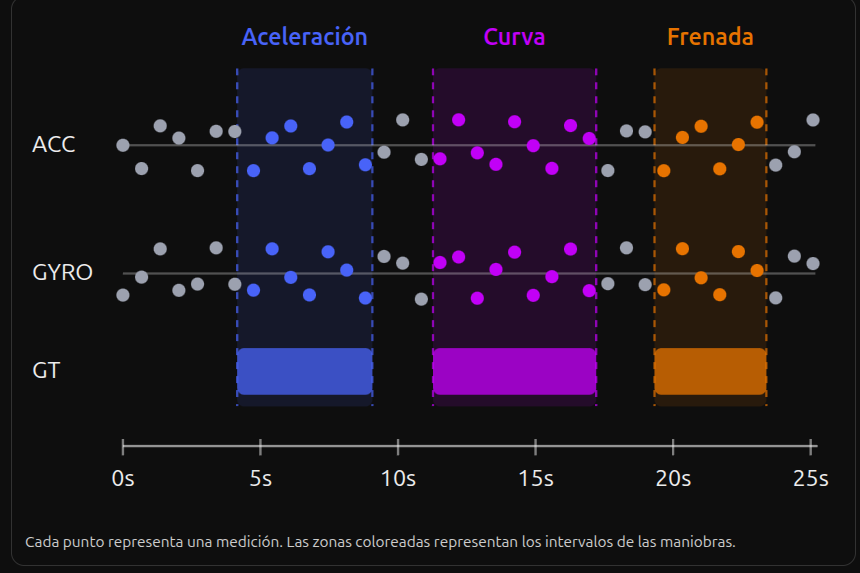

Seria el equivalente a abrir las cajas antes de pesarlas para confirmar que ninguna vino vacía ni a medio llenar. Segun la informacion que recolecte, en ciencia de datos con sensores reales, estos chequeos de cinco líneas ahorran muchísimo tiempo de depuración porque atrapan errores de alineación justo donde nacen, antes de que se camuflen como malos resultados en el modelo.

In [15]:
viajes_data = {}
resumen_viajes = []

# iteramos sobre los IDs de viaje
for trip_id in TRIPS:
    trip_path = GITHUB_DIR / trip_id

    # Obtenemos el tiempo de referencia del viaje
    with open(trip_path / "viagem.json", "r", encoding="utf-8") as f:
        meta = json.load(f)
    t0_nanos = meta["firstCollectionUptimeNanos"] # Tiempo inicial en nanosegundos de la recolección de datos del viaje

    # Carga de sensores
    acc = pd.read_csv(trip_path / "aceleracaoLinear_terra.csv")
    gyro = pd.read_csv(trip_path / "giroscopio_terra.csv")
    
    # Conversión a segundos desde t0
    acc["t_sec"] = (acc["uptimeNanos"] - t0_nanos) / 1e9 # Tiempo en segundos desde el inicio del viaje
    gyro["t_sec"] = (gyro["uptimeNanos"] - t0_nanos) / 1e9

    # Carga de etiquetas (limpiamos espacios en encabezados y textos)
    gt = pd.read_csv(trip_path / "groundTruth.csv")
    gt.columns = gt.columns.str.strip()
    for col in gt.select_dtypes(include="object").columns:
        gt[col] = gt[col].str.strip()
    
    # Almacenamos los datos del viaje
    viajes_data[trip_id] = {"acc": acc, "gyro": gyro, "gt": gt}

    # chequeamos mínimo de muestras por evento en este viaje 
    muestras_acc = [
        ((acc["t_sec"] >= r["inicio"]) & (acc["t_sec"] <= r["fim"])).sum()
        for _, r in gt.iterrows()
    ]
    muestras_gyro = [
        ((gyro["t_sec"] >= r["inicio"]) & (gyro["t_sec"] <= r["fim"])).sum()
        for _, r in gt.iterrows()
    ]
    
    # Almacenamos el resumen del viaje
    resumen_viajes.append({
        "trip_id": trip_id,
        "eventos": len(gt),
        "min_muestras_acc": min(muestras_acc),
        "min_muestras_gyro": min(muestras_gyro),
    })

print("Columnas acc  :", list(viajes_data["16"]["acc"].columns))
print("Columnas gyro :", list(viajes_data["16"]["gyro"].columns))
print("Columnas gt   :", list(viajes_data["16"]["gt"].columns))
display(pd.DataFrame(resumen_viajes))
print(f"Total de eventos cargados: {sum(r['eventos'] for r in resumen_viajes)}")

Columnas acc  : ['timestamp', 'uptimeNanos', 'x', 'y', 'z', 't_sec']
Columnas gyro : ['timestamp', 'uptimeNanos', 'x', 'y', 'z', 't_sec']
Columnas gt   : ['evento', 'inicio', 'fim']


,trip_id,eventos,min_muestras_acc,min_muestras_gyro
0,16,16,97,97
1,17,14,97,97
2,20,17,107,107
3,21,22,82,82


Total de eventos cargados: 69


La sincronización de los 4 viajes dio excelente, con un mínimo 82 muestras por evento y conteo idéntico en ambos sensores, sin huecos ni cortes

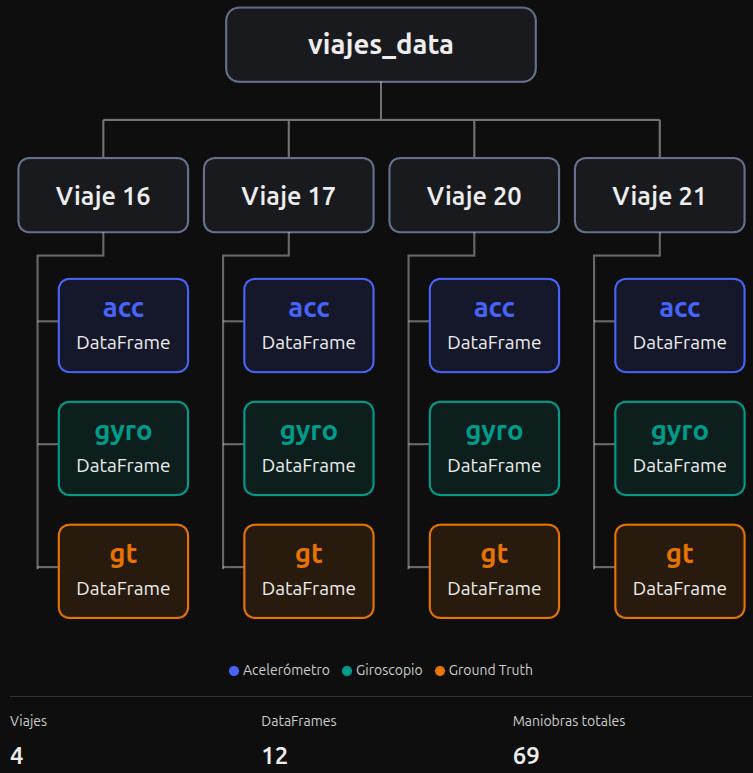

La ventaja de esta organización es que mantenemos separados los datos de cada viaje, facilitando la posterior segmentación de las maniobras, extracción de características y partición mediante GroupKFold o StratifiedGroupKFold, evitando que un mismo viaje aparezca simultáneamente en entrenamiento y evaluación.

Dado que el dataset de GitHub cuenta con 69 eventos etiquetados y registra aceleraciones en coordenadas terrestres (_terra), no es válido usar los ejes x e y crudos porque dependen del rumbo geográfico del vehículo, por ello se optara por construir variables inflexibles a la orientación (magnitud horizontal y estadísticos del eje vertical z). Adicionalmente, se podria incorporar el ángulo neto de rotación en Z (gyro_z_mean × duración) para diferenciar maniobras de giro sostenido (curvas) de maniobras de ida y vuelta donde la rotación neta se cancela (cambios de carril)

¿Por cuales características optaremos?
- Magnitudes horizontales (acc_mag_xy y gyro_mag_xy): nos permitirán medir la intensidad del movimiento independientemente del rumbo del vehículo.
- Eje z con signo: conserva una referencia vertical independiente del rumbo y, en el caso del giroscopio, permite distinguir el sentido de giro, como vimos anteriormente.
- Rotación neta (gyro_z_net_rad): luego de analizar distintas características descriptivas, optamos por incluir la rotación neta, ya que estima el ángulo total girado y permite diferenciar las curvas de los cambios de carril, donde el giro y el contragiro tienden a cancelarse.
- Rango de aceleración horizontal (acc_mag_xy_range): el rango tampoco recupera el signo perdido ni garantiza distinguir una aceleración de una frenada. Simplemente aporta información adicional sobre la amplitud de la señal, evitando amplificar el ruido mediante diferencias entre muestras consecutivas.

Esta celda transforma los datos crudos de los cuatro viajes en un único DataFrame donde cada fila representa una maniobra completa y cada columna una característica física de esa maniobra.

En lugar de guardar todas las mediciones de cada segmento, las resumimos mediante características descriptivas.

In [17]:
# Extracción de features por evento
filas_eventos = []

# Iteramos sobre cada viaje y sus eventos para extraer las features fisicas
for trip_id, datos in viajes_data.items():
    acc = datos["acc"]
    gyro = datos["gyro"]
    gt = datos["gt"] # aca estan los eventos de cada viaje
    
    # Iteramos sobre cada evento del viaje
    for idx, row in gt.iterrows():
        inicio, fim = row["inicio"], row["fim"] 
        duracion = fim - inicio # Duración del evento en segundos

        # Recorte del evento en ambos sensores
        seg_acc = acc[(acc["t_sec"] >= inicio) & (acc["t_sec"] <= fim)]
        seg_gyro = gyro[(gyro["t_sec"] >= inicio) & (gyro["t_sec"] <= fim)]

        # Magnitudes horizontales (eliminan dependencia de orientación Norte/Este)
        acc_mag_xy = np.hypot(seg_acc["x"], seg_acc["y"])
        gyro_mag_xy = np.hypot(seg_gyro["x"], seg_gyro["y"])

        # Rotación neta en Z (estima el ángulo total girado: separa curvas de cambios de carril)
        gyro_z_mean = seg_gyro["z"].mean()
        gyro_z_net_rad = gyro_z_mean * duracion 
        
        # Guardamos las features extraídas en un diccionario por evento
        filas_eventos.append({
            # Metadatos (no entran como features al modelo).
            "trip_id": trip_id,
            "event_id": f"{trip_id}_{idx:02d}",
            "target": row["evento"],

            # Duración del evento
            "duracion_sec": duracion,

            # Aceleración horizontal (magnitud y amplitud)
            "acc_mag_xy_mean": acc_mag_xy.mean(),
            "acc_mag_xy_std": acc_mag_xy.std(),
            "acc_mag_xy_max": acc_mag_xy.max(),
            "acc_mag_xy_median": acc_mag_xy.median(),
            "acc_mag_xy_range": acc_mag_xy.max() - acc_mag_xy.min(),

            # Aceleración vertical (referencia invariante al rumbo)
            "acc_z_mean": seg_acc["z"].mean(),
            "acc_z_std": seg_acc["z"].std(),
            "acc_z_min": seg_acc["z"].min(),
            "acc_z_max": seg_acc["z"].max(),

            # Velocidad angular vertical
            "gyro_z_mean": gyro_z_mean,
            "gyro_z_std": seg_gyro["z"].std(),
            "gyro_z_min": seg_gyro["z"].min(),
            "gyro_z_max": seg_gyro["z"].max(),
            "gyro_z_abs_mean": seg_gyro["z"].abs().mean(),
            "gyro_z_net_rad": gyro_z_net_rad,

            # Velocidad angular horizontal
            "gyro_mag_xy_mean": gyro_mag_xy.mean(),
            "gyro_mag_xy_std": gyro_mag_xy.std(),
            "gyro_mag_xy_max": gyro_mag_xy.max(),
        })

# Creamos un DataFrame final con todas las filas de eventos
df_github_events = pd.DataFrame(filas_eventos)

print(f"Shape final  : {df_github_events.shape} (69 eventos, 3 metadatos/target + 19 features)")
print(f"Nulos totales: {df_github_events.isna().sum().sum()}")

Shape final  : (69, 22) (69 eventos, 3 metadatos/target + 19 features)
Nulos totales: 0


la incorporacion fue exitosa: 69 maniobras, 19 features y se agregaron 3 columnas nuevas (no deben utilizarse como variables predictoras):
1) trip_id:	Identificar el viaje de procedencia.
2) event_id: Identificar de manera única la maniobra.
3) target: Identificar la clase de maniobra que queremos predecir.

mostramos las 5 primeras filas:

In [18]:
display(df_github_events.head(5))

,trip_id,event_id,target,duracion_sec,acc_mag_xy_mean,acc_mag_xy_std,acc_mag_xy_max,acc_mag_xy_median,acc_mag_xy_range,acc_z_mean,...,acc_z_max,gyro_z_mean,gyro_z_std,gyro_z_min,gyro_z_max,gyro_z_abs_mean,gyro_z_net_rad,gyro_mag_xy_mean,gyro_mag_xy_std,gyro_mag_xy_max
0,16,16_00,evento_nao_agressivo,4.5,0.695238,0.385326,1.591481,0.634223,1.511379,-0.020645,...,0.625705,0.003228,0.029655,-0.089333,0.089823,0.023092,0.014526,0.042059,0.032376,0.210707
1,16,16_01,curva_direita_agressiva,4.0,2.762686,1.077430,5.970734,2.753547,5.540056,0.431257,...,6.237326,-0.375732,0.287258,-1.274293,0.168457,0.387323,-1.502928,0.225570,0.189352,1.044080
2,16,16_02,evento_nao_agressivo,3.5,0.676171,0.363411,1.734778,0.636105,1.646779,-0.145029,...,0.599962,0.302688,0.215344,-0.184703,0.706751,0.317949,1.059410,0.053857,0.028958,0.166096
3,16,16_03,curva_direita_agressiva,3.0,2.666741,1.026936,6.713753,2.621550,6.555202,0.798090,...,5.234116,-0.478604,0.256713,-1.235266,0.051331,0.480042,-1.435811,0.263242,0.175459,0.852344
4,16,16_04,curva_esquerda_agressiva,4.5,2.661306,1.101094,6.544981,2.686322,6.239751,0.400173,...,7.802361,0.328421,0.281001,-0.187950,1.028191,0.350159,1.477893,0.212524,0.179890,0.983485


se ve todo bien, los eventos quedaron distribuidos asi entre las filas:

Filas 0 a 15: los 16 eventos del viaje 16.

Filas 16 a 29: los 14 eventos del viaje 17.

Filas 30 a 46: los 17 eventos del viaje 20.

Filas 47 a 68: los 22 eventos del viaje 21.

features incorporadas en el dataset:

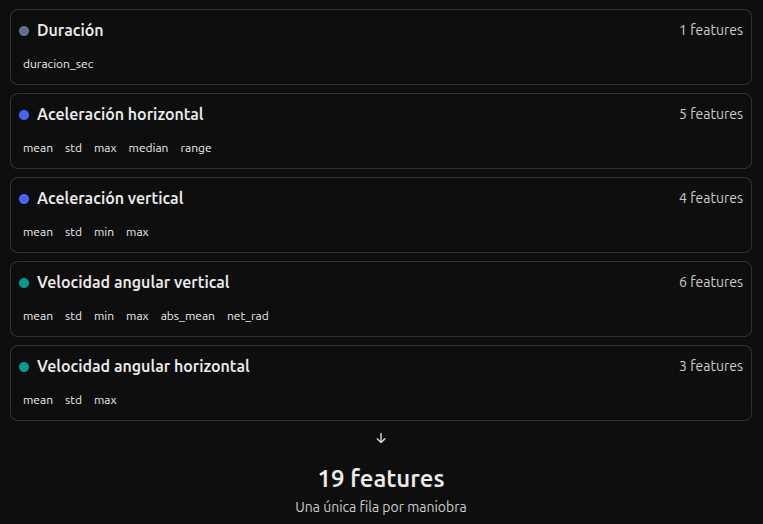

La ventaja principal de este procesamiento es que conseguimos representar maniobras de diferentes duraciones mediante una cantidad fija de características, conservando su procedencia para evitar el data leakage durante el particionamiento. A diferencia del dataset de Kaggle, donde cada fila representa una ventana de 14 muestras, en este dataset cada fila representa una maniobra completa, independientemente de su duración.

Antes de exportar el dataset, realizaremos dos comprobaciones mas:
- Colinealidad: identificaremos características altamente correlacionadas (|r| ≥ 0,90) para evaluar si existen variables redundantes que podamos eliminar.
- Valores atípicos: analizaremos el caso extremo de troca_faixa_esquerda_agressiva para determinar si corresponde a un error del sensor o a una maniobra real. Dado que esta clase contiene solo cuatro eventos, eliminar uno supondría perder el 25 % de sus observaciones.

In [21]:
# Diagnóstico de colinealidad 

META_COLS = ["trip_id", "event_id", "target"] # Columnas que no son features
feature_cols = [c for c in df_github_events.columns if c not in META_COLS]

# Pares con correlación alta
corr_gh = df_github_events[feature_cols].corr().abs()
pares_gh = []

# Extraemos solo la parte superior de la matriz de correlación para no repetir pares ni incluir la diagonal
for i in range(len(feature_cols)):
    for j in range(i + 1, len(feature_cols)):
        val = corr_gh.iloc[i, j]
        if val >= 0.90:
            pares_gh.append({
                "Feature_A": feature_cols[i],
                "Feature_B": feature_cols[j],
                "Corr_Abs": round(val, 4)
            })

df_pares_gh = pd.DataFrame(pares_gh).sort_values("Corr_Abs", ascending=False).reset_index(drop=True)
print(f"Pares con |r| >= 0.90 en GitHub: {len(df_pares_gh)}")
display(df_pares_gh)

Pares con |r| >= 0.90 en GitHub: 5


,Feature_A,Feature_B,Corr_Abs
0,acc_mag_xy_max,acc_mag_xy_range,0.9992
1,gyro_z_mean,gyro_z_net_rad,0.9912
2,acc_mag_xy_mean,acc_mag_xy_median,0.9827
3,gyro_mag_xy_std,gyro_mag_xy_max,0.9731
4,gyro_mag_xy_mean,gyro_mag_xy_std,0.9539


viendo estos 5 pares fuertemente correlacionados, procedemos a optar por la eliminacion de 5 caracteristicas que pensamos que podian aportar informacion, pero en este caso ensuciaran la clasificacion del modelo
1) acc_mag_xy_range: Aporta información muy similar al máximo.
2) gyro_z_mean: Priorizamos la rotación neta por su interpretación física.
3) acc_mag_xy_median: Presenta una alta correlación con la media.
4) gyro_mag_xy_std:	Presenta una alta correlación tanto con la media como con el máximo.

Inspección de los 4 eventos de troca_faixa_esquerda_agressiva (cambio de carril agresivo hacia la izquierda):

In [ ]:
print("\nEventos de 'troca_faixa_esquerda_agressiva':")
cols_ver = ["event_id", "duracion_sec", "acc_mag_xy_mean", "acc_mag_xy_max", "acc_mag_xy_range", "gyro_z_net_rad", "gyro_mag_xy_max"]
display(
    df_github_events[df_github_events["target"] == "troca_faixa_esquerda_agressiva"][cols_ver]
)


Eventos de 'troca_faixa_esquerda_agressiva':


,event_id,duracion_sec,acc_mag_xy_mean,acc_mag_xy_max,acc_mag_xy_range,gyro_z_net_rad,gyro_mag_xy_max
48,21_01,1.6,3.819328,8.067314,7.720544,0.045771,0.615578
50,21_03,2.3,2.748243,7.006192,6.847125,0.046445,0.504166
51,21_04,2.4,3.274599,11.551019,11.356463,0.009295,0.768164
53,21_06,2.1,4.407452,21.229618,21.014329,0.073395,1.700084


Aunque este cambio de carril presenta picos elevados de aceleración y velocidad angular, su duración, aceleración media y rotación neta son coherentes con los demás eventos de su clase. Esto sugiere que podría tratarse de una maniobra especialmente brusca y no necesariamente de un error del sensor. Por lo tanto, decidimos conservarlo, ya que eliminarlo implicaría perder el 25 % de los ejemplos de esa clase.
Además, comprobamos que gyro_z_net_rad permite diferenciar físicamente las curvas de los cambios de carril, cuya rotación neta es cercana a cero.

Procedemos a eliminar las columnas que mencionamos antes que no aportan nada, y tambien exportamos el dataset final de github

In [23]:
# Eliminación de columnas redundantes (decidida solo en train)
cols_drop_gh = [
    "acc_mag_xy_range",   # r = 0.9992 con acc_mag_xy_max
    "gyro_z_mean",        # r = 0.9912 con gyro_z_net_rad
    "acc_mag_xy_median",  # r = 0.9827 con acc_mag_xy_mean
    "gyro_mag_xy_std",    # r = 0.9731 con max y 0.9539 con mean
]

df_github_final = df_github_events.drop(columns=cols_drop_gh)

In [25]:
# Verificación final antes de guardar
assert df_github_final.isna().sum().sum() == 0
github_path = DATA_PROCESSED / "github_events_features.parquet"
df_github_final.to_parquet(github_path, index=False)

print(f"GitHub guardado  : {github_path.name} -> {df_github_final.shape}")
print(f"Features finales : {df_github_final.shape[1] - 3} + 3 metadatos/target (trip_id, event_id, target)")
print("\nDistribución de clases en GitHub:")
print(df_github_final["target"].value_counts())

print("\nResumen de archivos listos en data/processed/")
for p in sorted(DATA_PROCESSED.glob("*.parquet")):
    print(f" - {p.name}")

GitHub guardado  : github_events_features.parquet -> (69, 18)
Features finales : 15 + 3 metadatos/target (trip_id, event_id, target)

Distribución de clases en GitHub:
target
evento_nao_agressivo              14
aceleracao_agressiva              12
freada_agressiva                  12
curva_esquerda_agressiva          11
curva_direita_agressiva           11
troca_faixa_direita_agressiva      5
troca_faixa_esquerda_agressiva     4
Name: count, dtype: int64

Resumen de archivos listos en data/processed/
 - github_events_features.parquet
 - kaggle_test.parquet
 - kaggle_train.parquet
